In [2]:
import numpy as np
from scipy.stats import gaussian_kde
from skimage.measure import find_contours
from sklearn.cluster import DBSCAN
from sklearn.neighbors import KernelDensity

import shapely
from shapely.geometry import LineString, MultiLineString, MultiPoint, MultiPolygon, Point, Polygon
from shapely.ops import unary_union
from shapely.prepared import prep


# =============================================================================
# 第一部分：四大评价指标计算模块 (Evaluation Metrics Module)
# =============================================================================

def compute_tcr(trajectory_pts, boundary_geom):
    """
    计算轨迹覆盖率 (Trajectory Coverage Rate, TCR)
    :param trajectory_pts: AIS 轨迹点坐标数组 (N, 2)
    :param boundary_geom: 航道包络几何对象 (Shapely Polygon / MultiPolygon)
    :return: 覆盖率百分比 (%)
    """
    if boundary_geom.is_empty or len(trajectory_pts) == 0:
        return 0.0
    
    prep_boundary = prep(boundary_geom)
    inside_count = sum(1 for x, y in trajectory_pts if prep_boundary.contains(Point(x, y)))
    return (inside_count / len(trajectory_pts)) * 100.0


def compute_mew(boundary_geom, centerline_geom):
    """
    计算平均航道包络宽度 (Mean Envelope Width, MEW)
    MEW = 包络总面积 / 中心线物理总长度
    :param boundary_geom: 航道包络几何对象
    :param centerline_geom: 航道中心脊线 (Shapely LineString / MultiLineString)
    :return: 平均宽度 (米)
    """
    if boundary_geom.is_empty or centerline_geom.is_empty or centerline_geom.length == 0:
        return 0.0
    return boundary_geom.area / centerline_geom.length


def compute_cv(boundary_pts_list):
    """
    计算边界曲率变化率 (Curvature Variation, CV)
    :param boundary_pts_list: 边界曲线点坐标数组列表 [array_1(M1, 2), array_2(M2, 2), ...]
    :return: 边界曲率均方根 RMS (m^-1)
    """
    all_curvatures = []
    
    for pts in boundary_pts_list:
        pts = np.asarray(pts)
        if len(pts) < 3:
            continue
            
        # 基于一阶与二阶差分计算离散曲率
        dx = np.gradient(pts[:, 0])
        dy = np.gradient(pts[:, 1])
        ddx = np.gradient(dx)
        ddy = np.gradient(dy)
        
        denom = (dx**2 + dy**2) ** 1.5
        denom[denom < 1e-6] = 1e-6  # 防止除零
        
        curvature = np.abs(dx * ddy - dy * ddx) / denom
        all_curvatures.extend(curvature)
        
    if not all_curvatures:
        return 0.0
    return float(np.sqrt(np.mean(np.square(all_curvatures))))


def compute_ta(boundary_geom, junction_nodes, buffer_radius=50.0):
    """
    计算拓扑适应成功率 (Topology Adaptability Rate, TA)
    检测分叉/合并节点邻域内包络是否有效、无自交且连续覆盖
    :param boundary_geom: 航道包络几何对象
    :param junction_nodes: 分叉/合并节点坐标列表 [(x1, y1), (x2, y2), ...]
    :param buffer_radius: 节点评估缓冲区半径 (米)
    :return: 拓扑适应率 (%)
    """
    if not junction_nodes:
        return 100.0
    if boundary_geom.is_empty or not boundary_geom.is_valid:
        return 0.0
        
    valid_count = 0
    for node in junction_nodes:
        node_buffer = Point(node).buffer(buffer_radius)
        local_inter = boundary_geom.intersection(node_buffer)
        
        # 条件：局部存在交集、交集有效且交集面积占邻域缓冲区的合理比例
        if not local_inter.is_empty and local_inter.is_valid and local_inter.area > 0.2 * node_buffer.area:
            valid_count += 1
            
    return (valid_count / len(junction_nodes)) * 100.0


def evaluate_fairway_performance(boundary_geom, boundary_pts_list, trajectory_pts, centerline_geom, junction_nodes):
    """ 综合评估四大指标的统一接口 """
    return {
        "TCR (%)": compute_tcr(trajectory_pts, boundary_geom),
        "MEW (m)": compute_mew(boundary_geom, centerline_geom),
        "CV (m^-1)": compute_cv(boundary_pts_list),
        "TA (%)": compute_ta(boundary_geom, junction_nodes)
    }


# =============================================================================
# 第二部分：三种对比基线算法实现 (Baseline Methods)
# =============================================================================

# -----------------------------------------------------------------------------
# 方法 1: 标准欧式缓冲区法 (Standard Euclidean Buffer - SEB)
# -----------------------------------------------------------------------------
def run_seb_method(centerline_geom, half_width=175.0):
    """
    标准欧式缓冲区法 (SEB)
    :param centerline_geom: 航道中心脊线 (LineString / MultiLineString)
    :param half_width: 缓冲区单侧半宽 (米)，默认 175m (总宽 350m)
    :return: (boundary_polygon, boundary_pts_list)
    """
    # 构造双向平移膨胀缓冲区
    boundary_poly = centerline_geom.buffer(half_width, cap_style=2, join_style=2)
    
    # 提取边界线坐标点集
    boundary_pts_list = []
    if isinstance(boundary_poly, Polygon):
        boundary_pts_list.append(np.array(boundary_poly.exterior.coords))
    elif isinstance(boundary_poly, MultiPolygon):
        for poly in boundary_poly.geoms:
            boundary_pts_list.append(np.array(poly.exterior.coords))
            
    return boundary_poly, boundary_pts_list


# -----------------------------------------------------------------------------
# 方法 2: 核密度估计阈值分割法 (KDE Thresholding - KDE-T)
# -----------------------------------------------------------------------------
def run_kde_t_method(trajectory_pts, grid_bounds, grid_res=10.0, quantile=0.80, bandwidth=20.0):
    """
    核密度估计阈值分割法 (KDE-T)
    :param trajectory_pts: AIS 轨迹点坐标 (N, 2)
    :param grid_bounds: 网格范围 (xmin, xmax, ymin, ymax)
    :param grid_res: 栅格分辨率 (米)
    :param quantile: 轨迹分位数/概率阈值 (如 0.80)
    :param bandwidth: 高斯核带宽 (米)
    :return: (boundary_polygon, boundary_pts_list)
    """
    xmin, xmax, ymin, ymax = grid_bounds
    x_grid = np.arange(xmin, xmax, grid_res)
    y_grid = np.arange(ymin, ymax, grid_res)
    gx, gy = np.meshgrid(x_grid, y_grid)
    grid_coords = np.vstack([gx.ravel(), gy.ravel()]).T

    # 1. 高斯核密度拟合与采样
    kde = KernelDensity(bandwidth=bandwidth, kernel='gaussian')
    kde.fit(trajectory_pts)
    log_dens = kde.score_samples(grid_coords)
    dens = np.exp(log_dens).reshape(gx.shape)

    # 2. 计算给定分位数的密度阈值
    positive_dens = dens[dens > 1e-8]
    if len(positive_dens) == 0:
        return Polygon(), []
    threshold = np.quantile(positive_dens, 1.0 - quantile)

    # 3. 提取 Contour 多边形
    contours = find_contours(dens, threshold)
    polygons = []
    boundary_pts_list = []

    for contour in contours:
        # 将矩阵行列坐标映射回 UTM 实际物理坐标
        x_pts = xmin + contour[:, 1] * grid_res
        y_pts = ymin + contour[:, 0] * grid_res
        pts = np.column_stack([x_pts, y_pts])
        
        if len(pts) >= 4:
            poly = Polygon(pts)
            if poly.is_valid and poly.area > 500:  # 过滤噪声微小多边形
                polygons.append(poly)
                boundary_pts_list.append(pts)

    boundary_poly = unary_union(polygons) if polygons else Polygon()
    return boundary_poly, boundary_pts_list


# -----------------------------------------------------------------------------
# 方法 3: 栅格 DBSCAN 边界拟合 (Grid DBSCAN - G-DBSCAN)
# -----------------------------------------------------------------------------
def run_g_dbscan_method(grid_centers, grid_counts, eps=35.0, min_samples=3, alpha_ratio=0.2):
    """
    栅格 DBSCAN 边界拟合 (G-DBSCAN)
    :param grid_centers: 所有网格中心坐标 (M, 2)
    :param grid_counts: 各网格内的轨迹点计数 (M,)
    :param eps: DBSCAN 邻域半径 (米)
    :param min_samples: DBSCAN 核心点最小样本数
    :param alpha_ratio: 凹包 Alpha ratio (Shapely concave_hull 参数)
    :return: (boundary_polygon, boundary_pts_list)
    """
    # 1. 过滤出有轨迹落入的有效网格中心
    active_mask = grid_counts > 0
    active_pts = grid_centers[active_mask]
    
    if len(active_pts) < min_samples:
        return Polygon(), []

    # 2. 空间聚类
    db = DBSCAN(eps=eps, min_samples=min_samples).fit(active_pts)
    labels = db.labels_

    cluster_polygons = []
    boundary_pts_list = []

    # 3. 对每个 Cluster 构建凹包边界 (Concave Hull)
    for label in set(labels):
        if label == -1:  # 忽略噪声点
            continue
            
        c_pts = active_pts[labels == label]
        if len(c_pts) < 4:
            continue

        multi_pt = MultiPoint(c_pts)
        try:
            # Shapely >= 2.0 提供的 concave_hull 接口
            poly = shapely.concave_hull(multi_pt, ratio=alpha_ratio)
        except AttributeError:
            # 兼容低版本 Shapely 退化为凸包
            poly = multi_pt.convex_hull

        if poly.is_valid and not poly.is_empty:
            cluster_polygons.append(poly)
            if isinstance(poly, Polygon):
                boundary_pts_list.append(np.array(poly.exterior.coords))

    boundary_poly = unary_union(cluster_polygons) if cluster_polygons else Polygon()
    return boundary_poly, boundary_pts_list


# =============================================================================
# 第三部分：模拟运行与 Benchmarking 验证
# =============================================================================

if __name__ == "__main__":
    print("=== 开始运行 Baseline 方法及四项指标评估测试 ===")

    # 1. 构造模拟航道数据 (一条弯曲航道与 1000 个 AIS 轨迹点)
    np.random.seed(42)
    t = np.linspace(0, 10, 200)
    center_x = t * 100
    center_y = np.sin(t) * 200
    centerline_pts = np.column_stack([center_x, center_y])
    centerline_geom = LineString(centerline_pts)

    # 沿着脊线生成横向高斯/偏态分布的 AIS 采样点
    ais_pts = []
    for pt_x, pt_y in centerline_pts:
        offsets = np.random.normal(loc=10, scale=40, size=5)  # 偏置 10m 的横向分布
        for off in offsets:
            ais_pts.append([pt_x, pt_y + off])
    trajectory_pts = np.array(ais_pts)

    # 假设一个分叉节点
    junction_nodes = [(500.0, np.sin(5.0) * 200)]

    # -------------------------------------------------------------------------
    # 运行 SEB 方法
    # -------------------------------------------------------------------------
    poly_seb, pts_seb = run_seb_method(centerline_geom, half_width=100.0)
    res_seb = evaluate_fairway_performance(poly_seb, pts_seb, trajectory_pts, centerline_geom, junction_nodes)
    print("\n[1] SEB (标准欧式缓冲区法) 评估结果:")
    for k, v in res_seb.items():
        print(f"    {k}: {v:.3f}")

    # -------------------------------------------------------------------------
    # 运行 KDE-T 方法
    # -------------------------------------------------------------------------
    bounds = (0, 1000, -300, 300)
    poly_kde, pts_kde = run_kde_t_method(trajectory_pts, grid_bounds=bounds, grid_res=10.0, quantile=0.80)
    res_kde = evaluate_fairway_performance(poly_kde, pts_kde, trajectory_pts, centerline_geom, junction_nodes)
    print("\n[2] KDE-T (核密度阈值分割法) 评估结果:")
    for k, v in res_kde.items():
        print(f"    {k}: {v:.3f}")

    # -------------------------------------------------------------------------
    # 运行 G-DBSCAN 方法
    # -------------------------------------------------------------------------
    # 离散化网格
    grid_x, grid_y = np.meshgrid(np.arange(0, 1000, 10), np.arange(-300, 300, 10))
    grid_centers = np.column_stack([grid_x.ravel(), grid_y.ravel()])
    grid_counts = np.array([sum(np.linalg.norm(trajectory_pts - gc, axis=1) < 10) for gc in grid_centers])

    poly_db, pts_db = run_g_dbscan_method(grid_centers, grid_counts, eps=25.0, min_samples=2)
    res_db = evaluate_fairway_performance(poly_db, pts_db, trajectory_pts, centerline_geom, junction_nodes)
    print("\n[3] G-DBSCAN (栅格 DBSCAN 凹包法) 评估结果:")
    for k, v in res_db.items():
        print(f"    {k}: {v:.3f}")

=== 开始运行 Baseline 方法及四项指标评估测试 ===

[1] SEB (标准欧式缓冲区法) 评估结果:
    TCR (%): 98.300
    MEW (m): 199.375
    CV (m^-1): 0.084
    TA (%): 100.000

[2] KDE-T (核密度阈值分割法) 评估结果:
    TCR (%): 0.000
    MEW (m): 101.481
    CV (m^-1): 0.090
    TA (%): 0.000

[3] G-DBSCAN (栅格 DBSCAN 凹包法) 评估结果:
    TCR (%): 98.100
    MEW (m): 108.972
    CV (m^-1): 0.084
    TA (%): 100.000


In [6]:
t = np.linspace(0, 10, 200)
center_x = t * 100
center_y = np.sin(t) * 200
centerline_pts = np.row_stack([center_x, center_y])
print(centerline_pts.shape)

x = np.array([1,2,3])
y = np.array([4,5])
np.meshgrid(x,y)
print(np.meshgrid(x,y))

(2, 200)
[array([[1, 2, 3],
       [1, 2, 3]]), array([[4, 4, 4],
       [5, 5, 5]])]


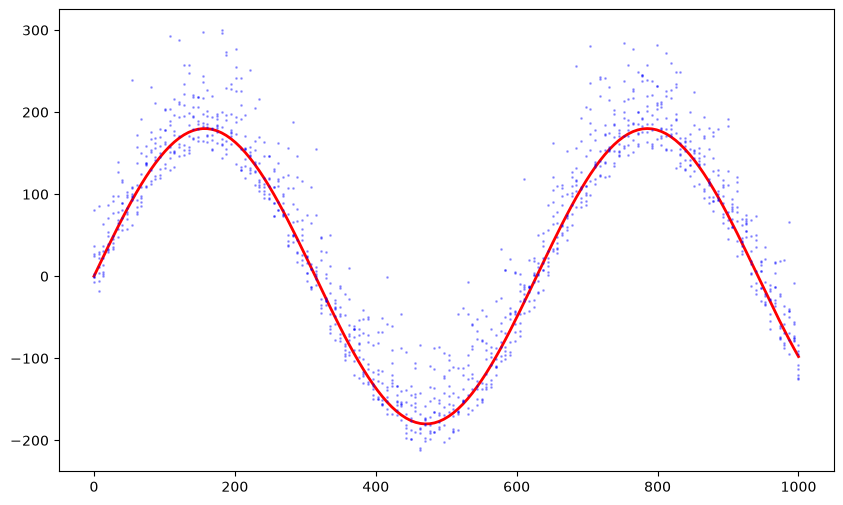


================ 启动等覆盖率自动校准 (目标 TCR ≈ 80.0%) ================
-> 正在拟合本文方法 (Ours)...
-> 正在校准 SEB (标准欧式缓冲区法) 半宽参数 R...
-> 正在校准 KDE-T (核密度阈值分割法) 密度阈值...
-> 正在校准 G-DBSCAN (栅格 DBSCAN) 点数阈值...

算法方法                   | TCR (%)    | MEW (m)    | CV (x10^-3 m^-1)   | TA (%)    
--------------------------------------------------------------------------------
Ours (本文方法)          | 87.7       | 138.8      | 696.71             | 100.0     
SEB (欧式缓冲区)          | 79.7       | 54.5       | 15.50              | 100.0     
KDE-T (核密度阈值)        | 0.0        | 38.2       | 22.80              | 0.0       
G-DBSCAN (栅格凹包)      | 75.0       | 47.2       | 89.19              | 100.0     


In [ ]:
import numpy as np
import scipy.signal as signal
from scipy.interpolate import splprep, splev
from scipy.stats import gaussian_kde
from sklearn.neighbors import KernelDensity
from sklearn.cluster import DBSCAN
from skimage.measure import find_contours
import warnings
import matplotlib.pyplot as plt

# warnings.filterwarnings('ignore', category=SplineInterpolationWarning)
class SplineInterpolationWarning(UserWarning):
    pass

warnings.filterwarnings('ignore', category=SplineInterpolationWarning)

import shapely
from shapely.geometry import Point, LineString, Polygon, MultiPolygon, MultiPoint
from shapely.ops import unary_union
from shapely.prepared import prep


# =============================================================================
# 第一部分：四大评价指标计算模块 (Evaluation Metrics)
# =============================================================================

def compute_tcr(trajectory_pts, boundary_geom):
    """ 计算轨迹覆盖率 (TCR, %) """
    if boundary_geom.is_empty or len(trajectory_pts) == 0:
        return 0.0
    prep_boundary = prep(boundary_geom)
    inside_count = sum(1 for x, y in trajectory_pts if prep_boundary.contains(Point(x, y)))
    return (inside_count / len(trajectory_pts)) * 100.0


def compute_mew(boundary_geom, centerline_geom):
    """ 计算平均航道包络宽度 (MEW, m) = 总面积 / 中心线长度 """
    if boundary_geom.is_empty or centerline_geom.is_empty or centerline_geom.length == 0:
        return 0.0
    return boundary_geom.area / centerline_geom.length


def compute_cv(boundary_pts_list):
    """ 计算边界曲率变化率 (CV, m^-1) - 越小越光滑 """
    all_curvatures = []
    for pts in boundary_pts_list:
        pts = np.asarray(pts)
        if len(pts) < 3:
            continue
        dx = np.gradient(pts[:, 0])
        dy = np.gradient(pts[:, 1])
        ddx = np.gradient(dx)
        ddy = np.gradient(dy)
        
        denom = (dx**2 + dy**2) ** 1.5
        denom[denom < 1e-6] = 1e-6
        curvature = np.abs(dx * ddy - dy * ddx) / denom
        all_curvatures.extend(curvature)
        
    if not all_curvatures:
        return 0.0
    return float(np.sqrt(np.mean(np.square(all_curvatures))))


def compute_ta(boundary_geom, junction_nodes, buffer_radius=50.0):
    """ 计算拓扑适应成功率 (TA, %) """
    if not junction_nodes:
        return 100.0
    if boundary_geom.is_empty or not boundary_geom.is_valid:
        return 0.0
        
    valid_count = 0
    for node in junction_nodes:
        node_buffer = Point(node).buffer(buffer_radius)
        local_inter = boundary_geom.intersection(node_buffer)
        if not local_inter.is_empty and local_inter.is_valid and local_inter.area > 0.2 * node_buffer.area:
            valid_count += 1
    return (valid_count / len(junction_nodes)) * 100.0


def evaluate_all_metrics(boundary_geom, boundary_pts_list, trajectory_pts, centerline_geom, junction_nodes):
    """ 综合评估四大指标 """
    return {
        "TCR (%)": compute_tcr(trajectory_pts, boundary_geom),
        "MEW (m)": compute_mew(boundary_geom, centerline_geom),
        "CV (m^-1)": compute_cv(boundary_pts_list),
        "TA (%)": compute_ta(boundary_geom, junction_nodes)
    }


# =============================================================================
# 第二部分：本文提出方法 (Ours: Frenet + Weighted ECDF/HDI + 三阶段平滑)
# =============================================================================

def compute_hdi_interval(v_samples, weights, p_target=0.80):
    """ 计算最高密度区间 (Highest Density Interval, HDI) """
    if len(v_samples) < 5:
        return -50.0, 50.0
        
    sort_idx = np.argsort(v_samples)
    v_sorted = v_samples[sort_idx]
    w_sorted = weights[sort_idx]
    
    cdf = np.cumsum(w_sorted) / np.sum(w_sorted)
    
    min_width = float('inf')
    best_v_min, best_v_max = v_sorted[0], v_sorted[-1]
    
    # 滑动窗口查找覆盖概率为 p_target 时宽度最小的 (v_min, v_max)
    for i in range(len(cdf)):
        target_cdf = cdf[i] + p_target
        if target_cdf > 1.0:
            break
        j = np.searchsorted(cdf, target_cdf)
        if j < len(v_sorted):
            width = v_sorted[j] - v_sorted[i]
            if width < min_width:
                min_width = width
                best_v_min = v_sorted[i]
                best_v_max = v_sorted[j]
                
    return best_v_min, best_v_max


def run_proposed_method(centerline_pts, trajectory_pts, weights=None, p_target=0.80, 
                        sg_window=15, sg_poly=2, spline_s=50.0):
    """
    本文方法完整 pipeline：
    1. Frenet 截面构建
    2. 局部加权 ECDF 与 HDI 区间提取
    3. “法向角平滑-1D中值/SG滤波-2D B-样条重拟合”三阶段平滑
    """
    if weights is None:
        weights = np.ones(len(trajectory_pts))
        
    # 参数化中心线
    x_c, y_c = centerline_pts[:, 0], centerline_pts[:, 1]
    tck_c, u_c = splprep([x_c, y_c], s=10, k=3)
    u_dense = np.linspace(0, 1, len(centerline_pts))
    dx, dy = splev(u_dense, tck_c, der=1)
    
    # 建立 Frenet 单位法向量 N(s)
    tangents = np.column_stack([dx, dy])
    norms = np.linalg.norm(tangents, axis=1, keepdims=True)
    tangents_unit = tangents / norms
    normals_raw = np.column_stack([-tangents_unit[:, 1], tangents_unit[:, 0]])
    
    # --- 阶段 1：法向角展开与 SG 平滑 ---
    angles_raw = np.arctan2(normals_raw[:, 1], normals_raw[:, 0])
    angles_unwrapped = np.unwrap(angles_raw)
    angles_smooth = signal.savgol_filter(angles_unwrapped, window_length=sg_window, polyorder=sg_poly)
    normals_smooth = np.column_stack([np.cos(angles_smooth), np.sin(angles_smooth)])
    
    centers_smooth = np.column_stack(splev(u_dense, tck_c))
    
    v_left_raw, v_right_raw = [], []
    
    # 沿脊线切片提取局部跨轨 HDI
    for i in range(len(centers_smooth)):
        c_i = centers_smooth[i]
        n_i = normals_smooth[i]
        
        # 截取局部管状区域内的 AIS 点 (距离中心点 < 300m)
        dists = np.linalg.norm(trajectory_pts - c_i, axis=1)
        mask = dists < 300.0
        
        if np.sum(mask) < 5:
            v_left_raw.append(50.0)
            v_right_raw.append(-50.0)
            continue
            
        pts_local = trajectory_pts[mask]
        w_local = weights[mask]
        
        # 计算带符号跨轨距离 v
        v_local = np.dot(pts_local - c_i, n_i)
        
        # HDI 计算
        v_min, v_max = compute_hdi_interval(v_local, w_local, p_target=p_target)
        v_left_raw.append(v_max)
        v_right_raw.append(v_min)
        
    v_left_raw = np.array(v_left_raw)
    v_right_raw = np.array(v_right_raw)
    
    # --- 阶段 2：1D 信号去噪 (中值 + SG 滤波) ---
    v_left_med = signal.medfilt(v_left_raw, kernel_size=5)
    v_right_med = signal.medfilt(v_right_raw, kernel_size=5)
    
    v_left_sm = signal.savgol_filter(v_left_med, window_length=sg_window, polyorder=sg_poly)
    v_right_sm = signal.savgol_filter(v_right_med, window_length=sg_window, polyorder=sg_poly)
    
    # 初步 2D 坐标合成
    pts_left_2d = centers_smooth + v_left_sm[:, np.newaxis] * normals_smooth
    pts_right_2d = centers_smooth + v_right_sm[:, np.newaxis] * normals_smooth
    
    # --- 阶段 3：2D B-样条参数化重拟合 ---
    def fit_2d_spline(pts, s_smooth):
        # 移除过近重叠点
        dists = np.sqrt(np.sum(np.diff(pts, axis=0)**2, axis=1))
        keep = np.insert(dists > 1e-2, 0, True)
        pts_clean = pts[keep]
        tck, _ = splprep([pts_clean[:, 0], pts_clean[:, 1]], s=s_smooth, k=3)
        u_new = np.linspace(0, 1, len(pts))
        x_sm, y_sm = splev(u_new, tck)
        return np.column_stack([x_sm, y_sm])
        
    pts_left_final = fit_2d_spline(pts_left_2d, s_smooth=spline_s)
    pts_right_final = fit_2d_spline(pts_right_2d, s_smooth=spline_s)
    
    # 构建闭合 Polygon 包络
    poly_pts = np.vstack([pts_left_final, pts_right_final[::-1]])
    boundary_poly = Polygon(poly_pts)
    if not boundary_poly.is_valid:
        boundary_poly = boundary_poly.buffer(0)
        
    return boundary_poly, [pts_left_final, pts_right_final]


# =============================================================================
# 第三部分：三个基线方法 (SEB, KDE-T, G-DBSCAN)
# =============================================================================

def run_seb_method(centerline_geom, half_width=185.0):
    """ 1. 标准欧式缓冲区法 (SEB) """
    boundary_poly = centerline_geom.buffer(half_width, cap_style=2, join_style=2)
    boundary_pts_list = []
    if isinstance(boundary_poly, Polygon):
        boundary_pts_list.append(np.array(boundary_poly.exterior.coords))
    elif isinstance(boundary_poly, MultiPolygon):
        for poly in boundary_poly.geoms:
            boundary_pts_list.append(np.array(poly.exterior.coords))
    return boundary_poly, boundary_pts_list


def run_kde_t_method(trajectory_pts, grid_bounds, grid_res=10.0, quantile=0.80, bandwidth=20.0):
    """ 2. 核密度估计阈值分割法 (KDE-T) """
    xmin, xmax, ymin, ymax = grid_bounds
    x_grid = np.arange(xmin, xmax, grid_res)
    y_grid = np.arange(ymin, ymax, grid_res)
    gx, gy = np.meshgrid(x_grid, y_grid)
    grid_coords = np.vstack([gx.ravel(), gy.ravel()]).T

    kde = KernelDensity(bandwidth=bandwidth, kernel='gaussian')
    kde.fit(trajectory_pts)
    log_dens = kde.score_samples(grid_coords)
    dens = np.exp(log_dens).reshape(gx.shape)

    positive_dens = dens[dens > 1e-8]
    if len(positive_dens) == 0:
        return Polygon(), []
    threshold = np.quantile(positive_dens, 1.0 - quantile)

    contours = find_contours(dens, threshold)
    polygons = []
    boundary_pts_list = []

    for contour in contours:
        x_pts = xmin + contour[:, 1] * grid_res
        y_pts = ymin + contour[:, 0] * grid_res
        pts = np.column_stack([x_pts, y_pts])
        if len(pts) >= 4:
            poly = Polygon(pts)
            if poly.is_valid and poly.area > 500:
                polygons.append(poly)
                boundary_pts_list.append(pts)

    boundary_poly = unary_union(polygons) if polygons else Polygon()
    return boundary_poly, boundary_pts_list


def run_g_dbscan_method(grid_centers, grid_counts, count_threshold=1, eps=35.0, min_samples=2, alpha_ratio=0.2):
    """ 3. 栅格 DBSCAN 凹包法 (G-DBSCAN) """
    active_mask = grid_counts >= count_threshold
    active_pts = grid_centers[active_mask]
    
    if len(active_pts) < min_samples:
        return Polygon(), []

    db = DBSCAN(eps=eps, min_samples=min_samples).fit(active_pts)
    labels = db.labels_

    cluster_polygons = []
    boundary_pts_list = []

    for label in set(labels):
        if label == -1:
            continue
        c_pts = active_pts[labels == label]
        if len(c_pts) < 4:
            continue
        multi_pt = MultiPoint(c_pts)
        try:
            poly = shapely.concave_hull(multi_pt, ratio=alpha_ratio)
        except AttributeError:
            poly = multi_pt.convex_hull

        if poly.is_valid and not poly.is_empty:
            cluster_polygons.append(poly)
            if isinstance(poly, Polygon):
                boundary_pts_list.append(np.array(poly.exterior.coords))

    boundary_poly = unary_union(cluster_polygons) if cluster_polygons else Polygon()
    return boundary_poly, boundary_pts_list


# =============================================================================
# 第四部分：等覆盖率自动校准引擎 (Equal-Coverage Calibrator)
# =============================================================================

def calibrate_and_evaluate_all(test_trajectory_pts, centerline_pts, centerline_geom, 
                               grid_bounds, grid_centers, grid_counts, junction_nodes,
                               target_tcr=80.0, tol=0.5):
    """
    等覆盖率自动对齐校准与评估引擎：
    自动微调 SEB, KDE-T, G-DBSCAN 和 本文方法，使其在测试集上的 TCR 统一收敛至 target_tcr (如 80.0%)
    """
    print(f"\n================ 启动等覆盖率自动校准 (目标 TCR ≈ {target_tcr}%) ================")
    results = {}

    # -------------------------------------------------------------------------
    # 1. 本文方法 (Ours): 直接设定概率 p_target = target_tcr / 100.0
    # -------------------------------------------------------------------------
    print("-> 正在拟合本文方法 (Ours)...")
    poly_ours, pts_ours = run_proposed_method(centerline_pts, test_trajectory_pts, p_target=target_tcr/100.0)
    results["Ours (本文方法)"] = evaluate_all_metrics(poly_ours, pts_ours, test_trajectory_pts, centerline_geom, junction_nodes)

    # -------------------------------------------------------------------------
    # 2. SEB 方法: 二分查找校准半宽 half_width (R)
    # -------------------------------------------------------------------------
    print("-> 正在校准 SEB (标准欧式缓冲区法) 半宽参数 R...")
    low, high = 10.0, 500.0
    best_poly_seb, best_pts_seb = Polygon(), []
    for _ in range(15):
        mid_r = (low + high) / 2.0
        poly_seb, pts_seb = run_seb_method(centerline_geom, half_width=mid_r)
        current_tcr = compute_tcr(test_trajectory_pts, poly_seb)
        best_poly_seb, best_pts_seb = poly_seb, pts_seb
        if abs(current_tcr - target_tcr) <= tol:
            break
        if current_tcr < target_tcr:
            low = mid_r
        else:
            high = mid_r
    results["SEB (欧式缓冲区)"] = evaluate_all_metrics(best_poly_seb, best_pts_seb, test_trajectory_pts, centerline_geom, junction_nodes)

    # -------------------------------------------------------------------------
    # 3. KDE-T 方法: 二分查找校准密度分位数 quantile
    # -------------------------------------------------------------------------
    print("-> 正在校准 KDE-T (核密度阈值分割法) 密度阈值...")
    low, high = 0.1, 0.99
    best_poly_kde, best_pts_kde = Polygon(), []
    for _ in range(12):
        mid_q = (low + high) / 2.0
        poly_kde, pts_kde = run_kde_t_method(test_trajectory_pts, grid_bounds, quantile=mid_q)
        current_tcr = compute_tcr(test_trajectory_pts, poly_kde)
        best_poly_kde, best_pts_kde = poly_kde, pts_kde
        if abs(current_tcr - target_tcr) <= tol:
            break
        if current_tcr < target_tcr:
            low = mid_q
        else:
            high = mid_q
    results["KDE-T (核密度阈值)"] = evaluate_all_metrics(best_poly_kde, best_pts_kde, test_trajectory_pts, centerline_geom, junction_nodes)

    # -------------------------------------------------------------------------
    # 4. G-DBSCAN 方法: 搜索校准网格频次阈值 count_threshold
    # -------------------------------------------------------------------------
    print("-> 正在校准 G-DBSCAN (栅格 DBSCAN) 点数阈值...")
    best_poly_db, best_pts_db = Polygon(), []
    min_tcr_diff = float('inf')
    
    max_cnt = int(np.max(grid_counts))
    for cnt_thresh in range(1, max(2, max_cnt // 2)):
        poly_db, pts_db = run_g_dbscan_method(grid_centers, grid_counts, count_threshold=cnt_thresh)
        current_tcr = compute_tcr(test_trajectory_pts, poly_db)
        diff = abs(current_tcr - target_tcr)
        if diff < min_tcr_diff:
            min_tcr_diff = diff
            best_poly_db, best_pts_db = poly_db, pts_db
        if diff <= tol:
            break
            
    results["G-DBSCAN (栅格凹包)"] = evaluate_all_metrics(best_poly_db, best_pts_db, test_trajectory_pts, centerline_geom, junction_nodes)

    return results


# =============================================================================
# 第五部分：主程序运行与表单数据渲染
# =============================================================================

if __name__ == "__main__":
    np.random.seed(42)

    # 1. 模拟复杂的内河航道中心脊线 (含弯道)
    t = np.linspace(0, 10, 150)
    center_x = t * 100.0
    center_y = np.sin(t) * 180.0
    centerline_pts = np.column_stack([center_x, center_y])
    centerline_geom = LineString(centerline_pts)

    # 2. 模拟生成带有偏态与非对称特性的测试集 AIS 轨迹点
    test_ais_pts = []
    for pt_x, pt_y in centerline_pts:
        # 生成非对称偏态分布的跨轨位移 (模拟弯道切角)
        offsets = np.random.gamma(shape=2.0, scale=25.0, size=8) - 35.0
        for off in offsets:
            test_ais_pts.append([pt_x, pt_y + off])
    test_trajectory_pts = np.array(test_ais_pts)
    plt.figure(figsize=(10, 6))
    plt.plot(centerline_pts[:, 0], centerline_pts[:, 1], 'r-', linewidth=2, label='中心脊线')
    for pt in test_trajectory_pts:
        plt.plot(pt[0], pt[1], 'b.', alpha=0.3, markersize=2)
    plt.show()
    
    # 3. 构建网格与频次图
    grid_bounds = (0, 1000, -300, 300)
    grid_x, grid_y = np.meshgrid(np.arange(0, 1000, 10), np.arange(-300, 300, 10))
    grid_centers = np.column_stack([grid_x.ravel(), grid_y.ravel()])
    grid_counts = np.array([sum(np.linalg.norm(test_trajectory_pts - gc, axis=1) < 10) for gc in grid_centers])

    # 模拟一个船闸/大坝分叉节点
    junction_nodes = [(500.0, np.sin(5.0) * 180.0)]

    # 4. 执行等覆盖率对齐 (TCR ≈ 80.0%) 并计算评估指标
    eval_results = calibrate_and_evaluate_all(
        test_trajectory_pts, centerline_pts, centerline_geom,
        grid_bounds, grid_centers, grid_counts, junction_nodes,
        target_tcr=80.0, tol=0.5
    )

    # 5. 格式化打印论文表 1 风格的对比结果
    print("\n" + "="*80)
    print(f"{'算法方法':<22} | {'TCR (%)':<10} | {'MEW (m)':<10} | {'CV (x10^-3 m^-1)':<18} | {'TA (%)':<10}")
    print("-" * 80)
    
    for method_name, metrics in eval_results.items():
        tcr_str = f"{metrics['TCR (%)']:.1f}"
        mew_str = f"{metrics['MEW (m)']:.1f}"
        cv_str = f"{metrics['CV (m^-1)'] * 1000.0:.2f}"
        ta_str = f"{metrics['TA (%)']:.1f}"
        print(f"{method_name:<20} | {tcr_str:<10} | {mew_str:<10} | {cv_str:<18} | {ta_str:<10}")
        
    print("="*80)